# Ship of Theseus corpus: lexical vs semantic decay, style vs content

Implements `docs/sot_analysis_plan.md` on the published English Ship of Theseus corpus (Tripto et al., 2024). Nothing is generated here: every text is from the corpus. This notebook produces the three figures in the final report.

1. **Data:** 7 datasets, 7 sources, 19,342 originals (T0), and 7 paraphraser variants × 3 chained rounds (T1–T3).
2. **Lexical vs semantic metrics:** BLEU, ROUGE-L and word retention (the "planks") vs BERTScore and a sentence-embedding cosine (the "hull"), T0 → T1/T2/T3, for ChatGPT, PaLM, Dipper and Pegasus (`decay_curves.png`).
3. **Style vs content decay:** does the meaning stay intact while the words and the style are replaced? (`style_vs_content.png`, `style_blocks_and_sources.png`)

In [1]:
import shutil
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pilot.config import ROOT, load_config, set_seeds
from pilot.metrics import DATASETS, bootstrap_mean_ci, load_corpus, load_reference

warnings.filterwarnings("ignore", category=FutureWarning)
cfg = load_config()
set_seeds(cfg["seed"])
SOT, DERIVED = cfg["paths"]["sot"], cfg["paths"]["derived"]
DERIVED.mkdir(parents=True, exist_ok=True)
OUT = cfg["paths"]["results"] / "sot_analysis"
OUT.mkdir(parents=True, exist_ok=True)

# Paraphrasers: the four primary variants, plus the intensity variants of Dipper and Pegasus.
PRIMARY = ["chatgpt", "palm", "dipper", "pegasus(full)"]
LABEL = {"chatgpt": "ChatGPT", "palm": "PaLM", "dipper": "Dipper", "pegasus(full)": "Pegasus",
         "dipper(low)": "Dipper (low)", "dipper(high)": "Dipper (high)", "pegasus(slight)": "Pegasus (slight)"}

# Categorical palette (validated: adjacent CVD ΔE 9.1, normal-vision 22.9; aqua/yellow < 3:1 contrast,
# so every chart carries direct labels and a CSV table). Color follows the paraphraser, in fixed order.
COLOR = {"chatgpt": "#2a78d6", "palm": "#eb6834", "dipper": "#1baf7a", "pegasus(full)": "#eda100"}
MARKER = {"chatgpt": "o", "palm": "s", "dipper": "^", "pegasus(full)": "D"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.labelsize": 9, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "lines.linewidth": 2, "lines.markersize": 6,
    "legend.frameon": False, "legend.fontsize": 8, "font.size": 9,
})

def label_ends(ax, items, x, min_gap=None, fmt="{label} {y:.2f}"):
    """Direct labels at line ends, nudged apart vertically so they never collide.
    items: list of (label, y, color-or-None)."""
    lo, hi = ax.get_ylim()
    gap = min_gap if min_gap is not None else 0.045 * (hi - lo)
    placed = []
    for label, y, _ in sorted(items, key=lambda t: t[1]):
        pos = max(y, placed[-1] + gap) if placed else y
        placed.append(pos)
        ax.annotate(fmt.format(label=label, y=y), (x, y), xytext=(x + 0.12, pos), textcoords="data",
                    va="center", fontsize=8, color=INK,
                    arrowprops=dict(arrowstyle="-", color=GRID, linewidth=0.6) if abs(pos - y) > 1e-9 else None)


def save(fig, name, table=None):
    fig.savefig(OUT / f"{name}.png")
    if table is not None:
        table.to_csv(OUT / f"{name}.csv", index=False)

print("results ->", OUT.relative_to(ROOT))

results -> results/sot_analysis


## 1. Data

All 7 datasets are copied from the upstream clone into git-ignored `data/sot/` (read-only), then loaded as one long table with one row per text: dataset, source, key, variant, round (0 = T0) and text. `train_datasets/` (never paraphrased, disjoint keys) is loaded as the **reference set**, used for normalization floors and for fitting style features.

In [2]:
for ds in DATASETS:
    for rel in (f"paraphrased_datasets/{ds}_paraphrased.csv", f"train_datasets/{ds}_train.csv"):
        dst = SOT / rel
        if not dst.exists():
            dst.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(cfg["paths"]["corpus_src"] / rel, dst)
            dst.chmod(0o444)

corpus = load_corpus(SOT)
reference = load_reference(SOT)
corpus["words"] = corpus.text.str.split().str.len()
reference["words"] = reference.text.str.split().str.len()

originals = corpus[corpus["round"] == 0]
summary = pd.DataFrame({
    "originals": originals.groupby("dataset").size(),
    "keys": originals.groupby("dataset").key.nunique(),
    "paraphrased_rows": corpus[corpus["round"] > 0].groupby("dataset").size(),
    "reference_texts": reference.groupby("dataset").size(),
    "median_T0_words": originals.groupby("dataset").words.median(),
})
summary.loc["total"] = [summary.originals.sum(), summary["keys"].sum(), summary.paraphrased_rows.sum(),
                        summary.reference_texts.sum(), originals.words.median()]
print(f"{len(corpus):,} corpus rows | {corpus.source.nunique()} sources | variants: {sorted(corpus.variant.unique())}")
summary.astype(int)

420,012 corpus rows | 7 sources | variants: ['chatgpt', 'dipper', 'dipper(high)', 'dipper(low)', 'original', 'palm', 'pegasus(full)', 'pegasus(slight)']


,originals,keys,paraphrased_rows,reference_texts,median_T0_words
dataset,,,,,
cmv,1626,256,33779,1666,295
eli5,3160,475,66110,3181,160
sci_gen,2797,471,57369,2780,181
tldr,2444,382,51075,2559,113
wp,2768,469,55649,2754,330
xsum,3227,476,67161,3243,162
yelp,3320,491,69527,3344,121
total,19342,3020,400670,19527,172


In [3]:
ID = ["dataset", "source", "key"]
chains = corpus[corpus["round"] > 0]

## 2. Lexical vs semantic metrics

**Scope.** PaLM chains are often incomplete (only 87.5% of originals reach T3), so the comparison uses **completer originals only**: those that all four primary paraphrasers (ChatGPT, PaLM, Dipper, Pegasus-full) carry to T3, and that have a T0 text. Every paraphraser is then scored on exactly the same texts. `SCOPE = "full"` keeps all 16,682 of them; `SCOPE = "sample"` draws 60 keys per dataset (seeded) and keeps every completer original of those keys.

At full scope the slow scores come from background scripts (`scripts/score_lexical.py full`, `scripts/score_semantic.py`, `scripts/style_features.py`), which write the caches the cells below read.

**Pairs.**
- *Cumulative:* T0 vs Tn, n = 1, 2, 3 (the decay curve).
- *Step:* Tn−1 vs Tn, n = 2, 3 (how much each extra round changes; for n = 1, step = cumulative).
- *Floor:* 200 unrelated **T0** pairs per dataset (two originals from different keys).

**Metrics (team standard, `docs/metric_standard.md`).** Word retention counts content words only (stop words excluded). BERTScore is baseline-rescaled. MPNet cosine embeds long texts as a token-weighted mean of sentence-packed 384-token chunks.

Scores are cached to `data/derived/sot_pairs_*.parquet`.

In [4]:
# SCOPE = "sample": 60 keys per dataset (fast; the original analysis).
# SCOPE = "full":   every completer original (the slow parts run as background scripts; see §2 notes).
SCOPE = "full"
N_KEYS = 60
VARIANTS = PRIMARY + ["dipper(low)", "dipper(high)", "pegasus(slight)"]
KEYS = ID + ["variant", "round", "kind"]
texts = corpus.set_index(ID + ["variant", "round"]).text  # (dataset, source, key, variant, round) -> text

reach_t3 = chains[(chains["round"] == 3) & chains.variant.isin(PRIMARY)].groupby(ID).variant.nunique()
completers = reach_t3[reach_t3 == len(PRIMARY)].reset_index()[ID]
# One chain (xsum / OpenAI / xsum-492) has all its paraphrases but no T0 text in the corpus; nothing to compare against.
completers = completers.merge(corpus.loc[corpus["round"] == 0, ID], on=ID)
if SCOPE == "full":
    sample = completers.copy()
else:
    rng = np.random.default_rng([cfg["seed"], 31])
    sample_keys = pd.concat([
        part.drop_duplicates("key").sample(N_KEYS, random_state=int(rng.integers(1e9)))[["dataset", "key"]]
        for _, part in completers.groupby("dataset")
    ])
    sample = completers.merge(sample_keys, on=["dataset", "key"])

# Pairs (cumulative T0 vs Tn, step Tn-1 vs Tn), built by the same function the background scripts use.
from pilot.metrics import build_pairs, t0_floor_pairs
pairs = build_pairs(corpus, sample, VARIANTS)

# Floor (team standard): 200 unrelated T0 pairs per dataset, two originals from different keys (articles).
floors = t0_floor_pairs(corpus, 200, cfg["seed"])

# The background scoring scripts (scripts/score_semantic.py, scripts/style_features.py) read these.
SAMPLE_PATH, FLOORS_PATH = DERIVED / "sot_sample.parquet", DERIVED / "sot_floors.parquet"
sample.to_parquet(SAMPLE_PATH, index=False)
floors.to_parquet(FLOORS_PATH, index=False)

print(f"SCOPE={SCOPE} | completer originals: {len(completers):,} of {len(originals):,} | analysed: {len(sample):,} originals "
      f"on {sample[['dataset', 'key']].drop_duplicates().shape[0]:,} keys | pairs: {len(pairs):,} | floor pairs: {len(floors)}")
sample.groupby(["dataset"]).size().to_frame("originals").T

SCOPE=full | completer originals: 16,682 of 19,342 | analysed: 16,682 originals on 2,996 keys | pairs: 583,870 | floor pairs: 1400


dataset,cmv,eli5,sci_gen,tldr,wp,xsum,yelp
originals,1490,3066,1634,2333,1922,3005,3232


In [5]:
import time

from pilot.metrics import score_lexical_chunked

LEX_CACHE = DERIVED / f"sot_pairs_lexical_{SCOPE}.parquet"  # one file per scope
FLOOR_LEX_CACHE = DERIVED / "sot_floors_lexical_t0.parquet"  # floors = unrelated T0 pairs (team standard)

# Chunked, bounded-memory scoring: feeding all 580k full-scope pairs to a process pool at once
# exhausted memory and killed the kernel. SCOPE="full" comes from `python scripts/score_lexical.py`.
started = time.time()
if not LEX_CACHE.exists():
    if SCOPE == "full":
        raise RuntimeError("run `python scripts/score_lexical.py full` in the background, then re-run this cell")
    score_lexical_chunked(pairs, LEX_CACHE)
if not FLOOR_LEX_CACHE.exists():
    score_lexical_chunked(floors.assign(source="", key="", variant="", round=0, kind="floor"), FLOOR_LEX_CACHE)
lex = pd.read_parquet(LEX_CACHE)
floor_lex = pd.read_parquet(FLOOR_LEX_CACHE)
assert len(lex) == len(pairs) and len(floor_lex) == len(floors)
print(f"lexical scores: {len(lex):,} pairs + {len(floor_lex):,} floor pairs in {time.time() - started:.0f}s")
# word_retention = content-word (stop words excluded) type recall, per the team standard.
LEXICAL = ["bleu", "rouge1", "rouge2", "rougeL", "word_retention"]
lex[lex.kind == "cumulative"].groupby(["variant", "round"])[LEXICAL].mean().round(3)

lexical scores: 583,870 pairs + 1,400 floor pairs in 0s


bleu  rouge1  rouge2  rougeL  word_retention
variant         round                                               
chatgpt         1      0.234   0.613   0.338   0.504           0.547
                2      0.212   0.591   0.310   0.469           0.528
                3      0.177   0.556   0.269   0.429           0.479
dipper          1      0.196   0.607   0.303   0.372           0.463
                2      0.113   0.519   0.203   0.313           0.346
                3      0.079   0.469   0.158   0.254           0.286
dipper(high)    1      0.016   0.242   0.029   0.127           0.052
                2      0.008   0.191   0.017   0.104           0.029
                3      0.005   0.152   0.012   0.088           0.019
dipper(low)     1      0.519   0.822   0.650   0.709           0.758
                2      0.396   0.754   0.537   0.621           0.667
                3      0.330   0.711   0.473   0.560           0.612
palm            1      0.429   0.709   0.544   0.647           0.658
                2      0.349   0.650   0.461   0.574           0.586
                3      0.313   0.623   0.424   0.540           0.554
pegasus(full)   1      0.424   0.781   0.610   0.672           0.688
                2      0.313   0.696   0.495   0.586           0.582
                3      0.267   0.657   0.449   0.540           0.537
pegasus(slight) 1      0.843   0.941   0.898   0.916           0.919
                2      0.732   0.896   0.821   0.853           0.857
                3      0.646   0.859   0.759   0.802           0.806

In [6]:
import importlib

import pilot.metrics
importlib.reload(pilot.metrics)
from pilot.metrics import chain_jobs, score_semantic

# v2 = team standard: rescaled BERTScore + MPNet cosine as a token-weighted mean of sentence-packed chunks.
SEM_CACHE, FLOOR_SEM_CACHE = DERIVED / "sot_pairs_semantic_v2.parquet", DERIVED / "sot_floors_semantic_v2.parquet"
SEMANTIC = ["bertscore_f1_rescaled", "bertscore_p_rescaled", "bertscore_r_rescaled", "mpnet_cosine"]

def floor_jobs(frame):
    for r in frame.itertuples(index=False):
        yield {"dataset": r.dataset, "floor_id": r.floor_id}, [r.ref, r.hyp], [(0, 1, {"kind": "floor"})]

# The cache is keyed by original and resumable, and a full-corpus cache also serves the sample.
# SCOPE="sample" computes missing scores here (about 1-2 h on MPS);
# SCOPE="full" (about 9 h) must come from `python scripts/score_semantic.py`, never from the kernel.
def semantic_missing():
    if not (SEM_CACHE.exists() and FLOOR_SEM_CACHE.exists()):
        return len(sample)
    cached = pd.read_parquet(SEM_CACHE, columns=ID).drop_duplicates()
    return len(sample.merge(cached, on=ID, how="left", indicator=True).query("_merge == 'left_only'"))

missing = semantic_missing()
if missing and SCOPE == "full":
    raise RuntimeError(f"{missing:,} originals lack semantic scores: run `python scripts/score_semantic.py` "
                       "in the background (resumable), then re-run from this cell")
if missing:
    score_semantic(chain_jobs(sample, texts, VARIANTS, ID), SEM_CACHE, ID)
    score_semantic(floor_jobs(floors), FLOOR_SEM_CACHE, ["dataset", "floor_id"])
sem = pd.read_parquet(SEM_CACHE).merge(sample, on=ID)  # only the originals in this scope
floor_sem = pd.read_parquet(FLOOR_SEM_CACHE)
assert len(floor_sem) == len(floors), "floor semantic cache is from another floor set; delete it and re-run"
print(f"semantic scores: {len(sem):,} pairs + {len(floor_sem):,} floor pairs")
sem[sem.kind == "cumulative"].groupby(["variant", "round"])[SEMANTIC].mean().round(3)

semantic scores: 583,870 pairs + 1,400 floor pairs


bertscore_f1_rescaled  bertscore_p_rescaled  \
variant         round                                                
chatgpt         1                      0.563                 0.604   
                2                      0.519                 0.563   
                3                      0.488                 0.533   
dipper          1                      0.441                 0.464   
                2                      0.346                 0.383   
                3                      0.279                 0.325   
dipper(high)    1                     -0.132                -0.116   
                2                     -0.148                -0.110   
                3                     -0.150                -0.092   
dipper(low)     1                      0.721                 0.742   
                2                      0.646                 0.680   
                3                      0.599                 0.642   
palm            1                      0.655                 0.713   
                2                      0.594                 0.659   
                3                      0.565                 0.633   
pegasus(full)   1                      0.603                 0.677   
                2                      0.509                 0.598   
                3                      0.467                 0.561   
pegasus(slight) 1                      0.880                 0.902   
                2                      0.803                 0.839   
                3                      0.745                 0.792   

                       bertscore_r_rescaled  mpnet_cosine  
variant         round                                      
chatgpt         1                     0.522         0.913  
                2                     0.476         0.899  
                3                     0.444         0.889  
dipper          1                     0.417         0.839  
                2                     0.308         0.788  
                3                     0.233         0.743  
dipper(high)    1                    -0.150         0.175  
                2                    -0.188         0.109  
                3                    -0.208         0.080  
dipper(low)     1                     0.700         0.937  
                2                     0.612         0.915  
                3                     0.556         0.898  
palm            1                     0.601         0.910  
                2                     0.532         0.891  
                3                     0.500         0.882  
pegasus(full)   1                     0.534         0.897  
                2                     0.427         0.861  
                3                     0.379         0.839  
pegasus(slight) 1                     0.859         0.974  
                2                     0.769         0.953  
                3                     0.700         0.937

In [7]:
import importlib
import json

import pilot.metrics
importlib.reload(pilot.metrics)
from pilot.metrics import STYLE_COMPONENTS, StyleScorer, extract_style, reference_subset, top_function_words, top_words

# Style = union of both team pipelines (see pilot.metrics.StyleScorer and STYLE_FAMILIES).
# v2 features add dependency-label and most-frequent-word rates (for dep_jsd and Burrows' Delta).
STYLE_CACHE, VOCAB_PATH = DERIVED / "sot_style_features_v2.parquet", DERIVED / "sot_style_vocab.json"
# Per-pair style scores take a while at full scope, so they are cached like the lexical scores.
STYLE_SCORES = DERIVED / f"sot_pairs_style_v2_{SCOPE}.parquet"
FLOOR_STYLE_SCORES = DERIVED / "sot_floors_style_v2.parquet"


def compute_style_scores():
    # The reference subset (train_datasets/, never paraphrased) fixes the function-word and MFW lists, the
    # z-scoring and the char n-gram vocabulary, so no rewritten output influences how style is measured.
    ref_sub = reference_subset(reference, 300, cfg["seed"])
    unique_texts = list(pd.unique(pd.concat([pairs.ref, pairs.hyp, floors.ref, floors.hyp, ref_sub.text])))

    # spaCy is slow; scripts/style_features.py computes the same cache with multiprocessing (which deadlocks
    # inside Jupyter on macOS). Without a cache, fall back to single-process extraction here.
    if STYLE_CACHE.exists():
        feats = pd.read_parquet(STYLE_CACHE)
    else:
        if SCOPE == "full":
            raise RuntimeError("run `python scripts/style_features.py` in the background, then re-run this cell")
        fw, mfw = top_function_words(ref_sub.text), top_words(ref_sub.text)
        feats = extract_style(unique_texts, fw, mfw)
        feats.to_parquet(STYLE_CACHE, index=False)
        VOCAB_PATH.write_text(json.dumps({"function_words": fw, "mfw": mfw}))
    scorer = StyleScorer(feats, ref_sub.text.tolist())
    # Keys come from `pairs` itself (row-aligned with the scores), never from another cache's row order.
    p = pairs.reset_index(drop=True)
    style = pd.concat([p[KEYS], scorer.score(p.ref, p.hyp)], axis=1)
    floor_style = pd.concat([floors[["dataset", "floor_id"]].reset_index(drop=True),
                             scorer.score(floors.ref.reset_index(drop=True), floors.hyp.reset_index(drop=True))], axis=1)
    return style, floor_style


if STYLE_SCORES.exists() and FLOOR_STYLE_SCORES.exists():
    style, floor_style = pd.read_parquet(STYLE_SCORES), pd.read_parquet(FLOOR_STYLE_SCORES)
    # The cache must cover exactly the current pairs (it is merged on keys downstream, never by position).
    assert len(style) == len(pairs) and style[KEYS].merge(pairs[KEYS]).shape[0] == len(pairs), "stale style cache; delete it"
    assert len(floor_style) == len(floors), "stale floor style cache; delete it"
else:
    style, floor_style = compute_style_scores()
    style.to_parquet(STYLE_SCORES, index=False); floor_style.to_parquet(FLOOR_STYLE_SCORES, index=False)
print(f"style scores: {len(style):,} pairs + {len(floor_style):,} floor pairs | components: {STYLE_COMPONENTS}")
style[style.kind == "cumulative"].groupby(["variant", "round"])[STYLE_COMPONENTS].mean().round(3)

style scores: 583,870 pairs + 1,400 floor pairs | components: ['style_surface', 'style_punctuation', 'punct_l1', 'style_function_words', 'fw_cosine', 'burrows_delta', 'style_syntax_pos', 'pos_jsd', 'dep_jsd', 'style_charngram', 'char3_cosine']


style_surface  style_punctuation  punct_l1  \
variant         round                                               
chatgpt         1              0.621              0.482     0.066   
                2              0.579              0.443     0.070   
                3              0.533              0.422     0.072   
dipper          1              0.707              0.428     0.077   
                2              0.630              0.351     0.084   
                3              0.578              0.306     0.089   
dipper(high)    1              0.120              0.064     0.123   
                2              0.093              0.052     0.132   
                3              0.078              0.039     0.143   
dipper(low)     1              0.883              0.614     0.056   
                2              0.838              0.537     0.065   
                3              0.808              0.497     0.069   
palm            1              0.792              0.590     0.057   
                2              0.741              0.518     0.064   
                3              0.717              0.487     0.067   
pegasus(full)   1              0.775              0.550     0.068   
                2              0.677              0.469     0.083   
                3              0.630              0.433     0.091   
pegasus(slight) 1              0.954              0.918     0.021   
                2              0.913              0.849     0.033   
                3              0.875              0.787     0.042   

                       style_function_words  fw_cosine  burrows_delta  \
variant         round                                                   
chatgpt         1                     0.551      0.834          0.349   
                2                     0.515      0.818          0.367   
                3                     0.476      0.804          0.387   
dipper          1                     0.566      0.834          0.363   
                2                     0.465      0.793          0.434   
                3                     0.408      0.767          0.474   
dipper(high)    1                     0.072      0.603          0.662   
                2                     0.038      0.543          0.710   
                3                     0.021      0.492          0.744   
dipper(low)     1                     0.812      0.924          0.180   
                2                     0.739      0.895          0.242   
                3                     0.694      0.878          0.278   
palm            1                     0.707      0.878          0.268   
                2                     0.639      0.851          0.314   
                3                     0.606      0.837          0.335   
pegasus(full)   1                     0.759      0.907          0.257   
                2                     0.660      0.864          0.333   
                3                     0.617      0.844          0.363   
pegasus(slight) 1                     0.943      0.976          0.078   
                2                     0.897      0.957          0.131   
                3                     0.856      0.941          0.171   

                       style_syntax_pos  pos_jsd  dep_jsd  style_charngram  \
variant         round                                                        
chatgpt         1                 0.682    0.024    0.058            0.679   
                2                 0.646    0.026    0.063            0.661   
                3                 0.619    0.029    0.068            0.627   
dipper          1                 0.668    0.027    0.059            0.617   
                2                 0.589    0.034    0.074            0.529   
                3                 0.538    0.040    0.084            0.478   
dipper(high)    1                 0.117    0.083    0.143            0.196   
                2                 0.073    0.103    0

In [8]:
# Samer's extra metrics: chrF, word edit rate and exact equality (scripts/score_extra.py lexical, local, ~4 min)
# plus entity/number/quantity recall, E5 cosine and sentence coverage (notebooks/colab_extra_scoring.ipynb).
EXTRA_FILES = {"scripts/score_extra.py lexical": ("sot_pairs_extra_lexical_full.parquet", "sot_floors_extra_lexical.parquet"),
               "notebooks/colab_extra_scoring.ipynb (download its outputs into data/derived/)":
                   ("sot_pairs_information_full.parquet", "sot_floors_information.parquet",
                    "sot_pairs_neural_extra.parquet", "sot_floors_neural_extra.parquet")}
missing_files = {how: [f for f in fs if not (DERIVED / f).exists()] for how, fs in EXTRA_FILES.items()}
missing_files = {how: fs for how, fs in missing_files.items() if fs}
if missing_files:
    raise RuntimeError("extra-metric caches missing; run: " + "; ".join(f"{how} -> {fs}" for how, fs in missing_files.items()))

EXTRA_LEX = ["chrf", "word_edit_rate", "exact_equal"]
INFO_COUNTS = ["entities_ref", "entities_lost", "numbers_ref", "numbers_lost", "numbers_added"]
INFORMATION = ["entity_recall", "number_recall", "quantity_recall", "sent_coverage"]
COVERAGE = ["sent_coverage", "min_sent_sim", "sentences_uncovered", "sentences_unsupported", "ref_sentences"]

xl = pd.read_parquet(DERIVED / "sot_pairs_extra_lexical_full.parquet")[KEYS + EXTRA_LEX]
xi = pd.read_parquet(DERIVED / "sot_pairs_information_full.parquet")[KEYS + INFO_COUNTS + INFORMATION[:3]]
xn = pd.read_parquet(DERIVED / "sot_pairs_neural_extra.parquet")[KEYS + ["e5_cosine"] + COVERAGE]
extra = (xl.merge(xi, on=KEYS, validate="1:1").merge(xn, on=KEYS, validate="1:1")
           .merge(pairs[KEYS], on=KEYS, validate="1:1"))      # only the pairs in this scope
assert len(extra) == len(pairs), "extra-metric caches don't cover every pair; re-run the scripts"

# Floor pairs: the CPU caches keep the floors' row order (like the lexical floors), the others carry floor_id.
floor_extra = (pd.read_parquet(DERIVED / "sot_floors_extra_lexical.parquet")[EXTRA_LEX]
               .assign(dataset=floors.dataset.to_numpy(), floor_id=floors.floor_id.to_numpy())
               .merge(pd.read_parquet(DERIVED / "sot_floors_information.parquet")[["dataset", "floor_id"] + INFORMATION[:3]],
                      on=["dataset", "floor_id"], validate="1:1")
               .merge(pd.read_parquet(DERIVED / "sot_floors_neural_extra.parquet")[["dataset", "floor_id", "e5_cosine", "sent_coverage"]],
                      on=["dataset", "floor_id"], validate="1:1"))
assert len(floor_extra) == len(floors)
print(f"extra metrics: {len(extra):,} pairs + {len(floor_extra):,} floor pairs")
extra[extra.kind == "cumulative"].groupby(["variant", "round"])[EXTRA_LEX + ["e5_cosine"] + INFORMATION].mean().round(3)

extra metrics: 583,870 pairs + 1,400 floor pairs


chrf  word_edit_rate  exact_equal  e5_cosine  \
variant         round                                                  
chatgpt         1      0.541           0.707        0.000      0.965   
                2      0.522           0.747        0.000      0.960   
                3      0.492           0.788        0.000      0.956   
dipper          1      0.496           0.878        0.000      0.946   
                2      0.408           0.889        0.000      0.928   
                3      0.360           0.923        0.000      0.914   
dipper(high)    1      0.231           1.029        0.000      0.756   
                2      0.171           0.993        0.000      0.732   
                3      0.129           0.984        0.000      0.719   
dipper(low)     1      0.731           0.500        0.001      0.979   
                2      0.644           0.599        0.000      0.971   
                3      0.593           0.669        0.000      0.966   
palm            1      0.639           0.533        0.000      0.967   
                2      0.578           0.623        0.000      0.959   
                3      0.550           0.666        0.000      0.955   
pegasus(full)   1      0.644           0.528        0.000      0.968   
                2      0.545           0.609        0.000      0.956   
                3      0.502           0.655        0.000      0.949   
pegasus(slight) 1      0.902           0.148        0.041      0.991   
                2      0.831           0.249        0.016      0.985   
                3      0.775           0.326        0.014      0.980   

                       entity_recall  number_recall  quantity_recall  \
variant         round                                                  
chatgpt         1              0.841          0.717            0.592   
                2              0.820          0.686            0.553   
                3              0.810          0.669            0.527   
dipper          1              0.580          0.377            0.195   
                2              0.460          0.245            0.100   
                3              0.385          0.185            0.070   
dipper(high)    1              0.033          0.007            0.003   
                2              0.011          0.001            0.000   
                3              0.005          0.000            0.000   
dipper(low)     1              0.791          0.611            0.407   
                2              0.719          0.497            0.291   
                3              0.677          0.435            0.231   
palm            1              0.789          0.678            0.515   
                2              0.752          0.626            0.444   
                3              0.736          0.602            0.415   
pegasus(full)   1              0.635          0.547            0.646   
                2              0.551          0.443            0.539   
                3              0.515          0.401            0.493   
pegasus(slight) 1              0.912          0.877            0.904   
                2              0.844          0.790            0.840   
                3              0.790          0.718            0.783   

                       sent_coverage  
variant         round                 
chatgpt         1              0.844  
                2              0.810  
                3              0.793  
dipper          1              0.779  
                2              0.650  
                3              0.554  
dipper(high)    1              0.047  
                2              0.016  
                3              0.007  
dipper(low)     1              0.926  
                2              0.889  
                3              0.859  
palm            1              0.828  
                2              0.785  
                3              0.765  
pegasus(full)   1              0.932  
        

### 2.1 One scale for every metric: retained share

Each metric is normalized per dataset against its **floor**: the mean score of 200 **unrelated T0 pairs** from that dataset (two originals from different keys). This follows the team metric standard (`docs/metric_standard.md`).

For similarities (BLEU, ROUGE, word retention, rescaled BERTScore, cosines), which score 1 for identical texts:
$$\text{retained} = \frac{s - \text{floor}}{1 - \text{floor}}$$
For distances (punctuation L1, POS/dependency JSD, Burrows' Delta), which score 0 for identical texts:
$$\text{retained} = \frac{\text{floor} - d}{\text{floor}}$$

Either way, **retained = 1 means identical to T0 and 0 means no closer than an unrelated original from the same dataset**. Lexical, semantic and style decay can then be compared on one axis, which raw scores don't allow.

**Combined style score.** The 11 style components (the union of both team pipelines) are grouped into five families: surface, punctuation, function words, syntax and character n-grams. Each family score is the mean of its components' retained scores, and `style` is the mean of the five family scores. Overlapping measures therefore don't get double weight.

In [9]:
from pilot.metrics import STYLE_FAMILIES, add_style_composite, retained

KEYS = ID + ["variant", "round", "kind"]
STYLE = STYLE_COMPONENTS
LEXICAL_ALL = LEXICAL + ["chrf", "word_edit_rate"]   # + Samer's lexical metrics
SEMANTIC_ALL = SEMANTIC + ["e5_cosine"]              # + Samer's E5 cosine
CORE = LEXICAL + SEMANTIC + STYLE                     # defined for every non-degenerate pair
METRICS = LEXICAL_ALL + SEMANTIC_ALL + STYLE + INFORMATION   # raw scores; each gets a *_ret column below
FAMILIES = [f"style_fam_{f}" for f in STYLE_FAMILIES]
RET_METRICS = METRICS + FAMILIES + ["style"]  # everything on the retained scale (style = combined score)
NAME = {"bleu": "BLEU", "rouge1": "ROUGE-1", "rouge2": "ROUGE-2", "rougeL": "ROUGE-L",
        "word_retention": "Word retention (content words)", "chrf": "chrF", "word_edit_rate": "Word edit rate",
        "bertscore_f1_rescaled": "BERTScore F1 (rescaled)", "bertscore_p_rescaled": "BERTScore precision (rescaled)",
        "bertscore_r_rescaled": "BERTScore recall (rescaled)", "mpnet_cosine": "MPNet cosine", "e5_cosine": "E5 cosine",
        "style": "Style (combined)",
        "style_surface": "Surface (z-cosine)", "style_punctuation": "Punctuation (z-cosine)", "punct_l1": "Punctuation L1",
        "style_function_words": "Function words (z-cosine)", "fw_cosine": "Function-word cosine",
        "burrows_delta": "Burrows' Delta", "style_syntax_pos": "POS (z-cosine)", "pos_jsd": "POS JSD",
        "dep_jsd": "Dependency JSD", "style_charngram": "Char 2-4-gram TF-IDF", "char3_cosine": "Char 3-gram cosine",
        "entity_recall": "Entity recall", "number_recall": "Number recall", "quantity_recall": "Quantity recall",
        "sent_coverage": "Sentence coverage",
        **{f"style_fam_{f}": f"Style: {f.replace('_', ' ')}" for f in STYLE_FAMILIES}}

scores = (lex.merge(sem, on=KEYS, how="left", validate="1:1")
             .merge(style, on=KEYS, how="left", validate="1:1")
             .merge(extra, on=KEYS, how="left", validate="1:1"))
assert len(scores) == len(lex), "pairs lost in the merge"
missing = scores[CORE + ["chrf", "word_edit_rate", "e5_cosine"]].isna().sum()
# Undefined, not missing: word retention when the reference has no content words, BERTScore precision
# when the output is empty, style distributions of an empty text (degenerate outputs). Left as NaN.
# Information recalls are undefined (NaN) whenever the original has no entities / numbers / quantities.
assert missing.sum() < 0.001 * len(scores) * len(missing), f"too many undefined scores: {missing[missing > 0].to_dict()}"
print("undefined scores (degenerate outputs, left as NaN):", missing[missing > 0].to_dict())
print("pairs with an information score defined:", scores[INFORMATION].notna().mean().round(3).to_dict())
p = pairs.reset_index(drop=True)
scores = scores.merge(p.assign(len_ratio=p.hyp.str.split().str.len() / p.ref.str.split().str.len())[KEYS + ["len_ratio"]],
                      on=KEYS, validate="1:1")

# Heuristic content warnings (Samer's definitions; warnings, not validated errors). Raw shares, not normalized.
scores["flag_entity_loss"] = scores.entities_lost.fillna(0) > 0
scores["flag_number_change"] = (scores.numbers_lost.fillna(0) + scores.numbers_added.fillna(0)) > 0
scores["flag_sentence_omission"] = scores.sentences_uncovered.fillna(0) > 0
FLAGS = ["flag_entity_loss", "flag_number_change", "flag_sentence_omission"]
scores["flag_any_content_warning"] = scores[FLAGS].any(axis=1)

# Floors: mean score of the unrelated T0 pairs of each dataset. Exception: word edit rate is unbounded
# (edits / ref words), and unrelated pairs with a very short reference reach 30-85, which drags the mean to ~2.6
# while the typical unrelated pair is ~1.0. Its floor is the median, so a near-total rewrite scores ~0 retained.
floor_all = (floor_lex.assign(floor_id=floors.floor_id.to_numpy())[["dataset", "floor_id"] + LEXICAL]
             .merge(floor_sem, on=["dataset", "floor_id"], validate="1:1")
             .merge(floor_style, on=["dataset", "floor_id"], validate="1:1")
             .merge(floor_extra, on=["dataset", "floor_id"], validate="1:1"))
MEDIAN_FLOOR = ["word_edit_rate"]
floor = floor_all.groupby("dataset")[METRICS].mean()
floor[MEDIAN_FLOOR] = floor_all.groupby("dataset")[MEDIAN_FLOOR].median()
for m in METRICS:
    scores[f"{m}_ret"] = retained(scores[m], scores.dataset.map(floor[m]), m)
scores = add_style_composite(scores)

floor.round(3).to_csv(OUT / "floors_by_dataset.csv")
print(f"{len(scores):,} scored pairs | floors (mean over datasets):")
floor.mean().round(3).to_frame("floor").T

undefined scores (degenerate outputs, left as NaN): {'word_retention': 70, 'bertscore_f1_rescaled': 21, 'bertscore_p_rescaled': 15, 'bertscore_r_rescaled': 6, 'fw_cosine': 491, 'pos_jsd': 21, 'dep_jsd': 21}
pairs with an information score defined: {'entity_recall': 0.768, 'number_recall': 0.482, 'quantity_recall': 0.222, 'sent_coverage': 1.0}
583,870 scored pairs | floors (mean over datasets):


,bleu,rouge1,rouge2,rougeL,word_retention,chrf,word_edit_rate,bertscore_f1_rescaled,bertscore_p_rescaled,bertscore_r_rescaled,...,burrows_delta,style_syntax_pos,pos_jsd,dep_jsd,style_charngram,char3_cosine,entity_recall,number_recall,quantity_recall,sent_coverage
floor,0.008,0.187,0.017,0.094,0.062,0.218,1.015,-0.147,-0.149,-0.145,...,0.634,0.174,0.076,0.128,0.193,0.477,0.011,0.054,0.0,0.008


### 2.2 Decay curves: planks vs hull

Mean retained share at T0–T3 for the four paraphrasers, with 95% bootstrap CIs (1,000 resamples of keys). The top row is lexical (the planks), the bottom row semantic and style. The table behind the figure is `decay_curves.csv`.

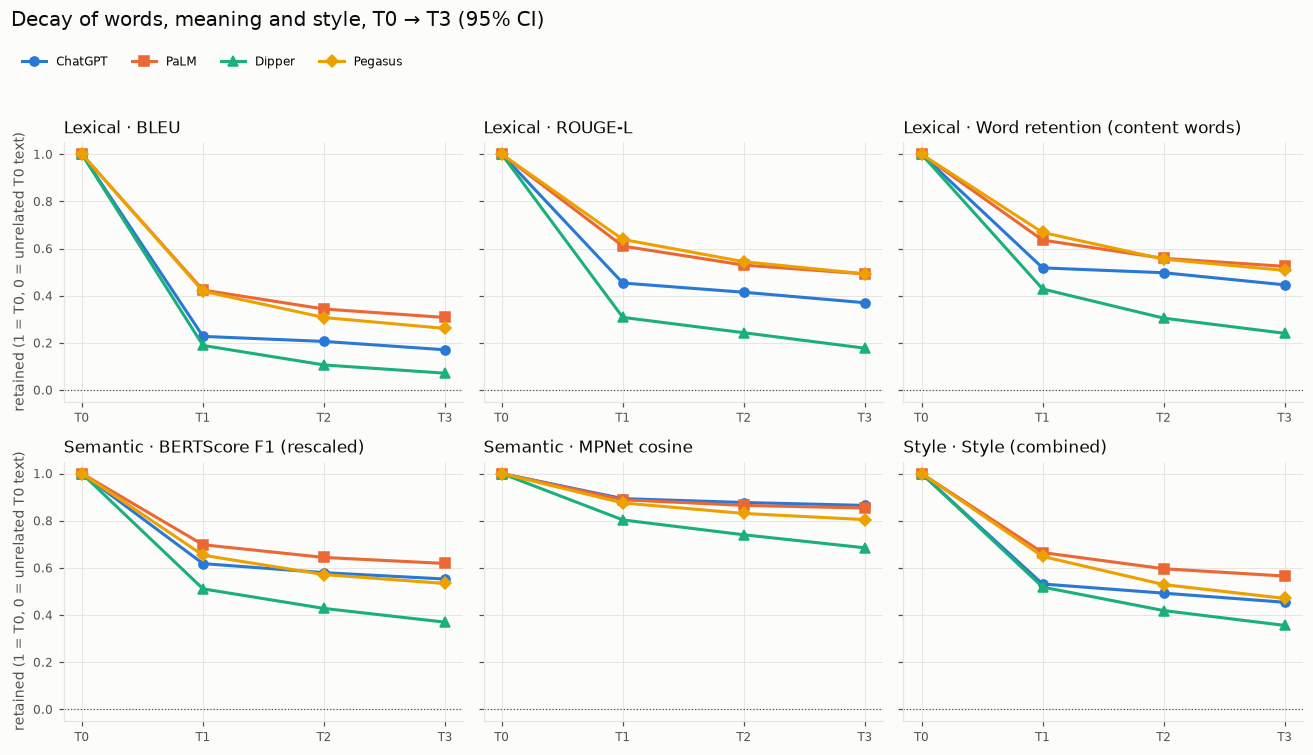

metric,bleu,rougeL,word_retention,bertscore_f1_rescaled,mpnet_cosine,style
variant,,,,,,
chatgpt,0.171,0.370,0.446,0.552,0.865,0.454
dipper,0.071,0.177,0.240,0.369,0.685,0.356
palm,0.308,0.492,0.524,0.619,0.854,0.565
pegasus(full),0.261,0.493,0.507,0.534,0.805,0.470


In [10]:
cum = scores[scores.kind == "cumulative"]
CURVE_METRICS = ["bleu", "rougeL", "word_retention", "bertscore_f1_rescaled", "mpnet_cosine", "style"]
curves = pd.concat([bootstrap_mean_ci(cum, ["variant", "round"], f"{m}_ret").assign(metric=m) for m in RET_METRICS],
                   ignore_index=True)
curves.to_csv(OUT / "decay_curves.csv", index=False)

def plot_curves(ax, metric, variants, colors, markers=None, styles=None):
    for v in variants:
        d = curves[(curves.metric == metric) & (curves.variant == v)].sort_values("round")
        ax.fill_between([0, *d["round"]], [1, *d.ci_low], [1, *d.ci_high], color=colors[v], alpha=0.15, linewidth=0)
        ax.plot([0, *d["round"]], [1, *d["mean"]], color=colors[v], marker=(markers or {}).get(v, "o"),
                linestyle=(styles or {}).get(v, "-"), label=LABEL[v])
    ax.set_xticks([0, 1, 2, 3], ["T0", "T1", "T2", "T3"]); ax.set_title(NAME[metric], loc="left")
    ax.axhline(0, color=MUTED, linewidth=0.8, linestyle=":")

PANEL_FAMILY = {"bleu": "Lexical", "rougeL": "Lexical", "word_retention": "Lexical",
                "bertscore_f1_rescaled": "Semantic", "mpnet_cosine": "Semantic", "style": "Style"}
fig, axes = plt.subplots(2, 3, figsize=(12, 6.8), sharey=True)
for ax, m in zip(axes.flat, CURVE_METRICS):
    plot_curves(ax, m, PRIMARY, COLOR, MARKER)
    ax.set_title(f"{PANEL_FAMILY[m]} · {NAME[m]}", loc="left")
for ax in axes[:, 0]:
    ax.set_ylabel("retained (1 = T0, 0 = unrelated T0 text)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.01, 0.955), ncol=4)
fig.suptitle("Decay of words, meaning and style, T0 → T3 (95% CI)", x=0.01, ha="left",
             fontsize=13, color=INK, y=1.0)
fig.tight_layout(rect=(0, 0, 1, 0.92))
save(fig, "decay_curves")
plt.show()
(curves[curves.metric.isin(CURVE_METRICS) & curves.variant.isin(PRIMARY) & (curves["round"] == 3)]
 .pivot(index="variant", columns="metric", values="mean")[CURVE_METRICS].round(3))

## 3. Style vs content decay: does the hull hold while the planks change?

On the retained scale, **content** = rescaled BERTScore F1 and **style** = the combined style score (§2.1): the mean of five family scores (surface, punctuation, function words, syntax, character n-grams), each averaging its components. Feature z-scores, the function-word and most-frequent-word lists and the char n-gram vocabulary are fitted on held-out reference texts.

- **3.1** Style vs content vs words per paraphraser, and the decay gap (content − style) with CIs.
- **3.2** Which style families and components go first, and does Human style decay differently from LLM style?

decay gap = retained content - retained style (mean [95% CI]):


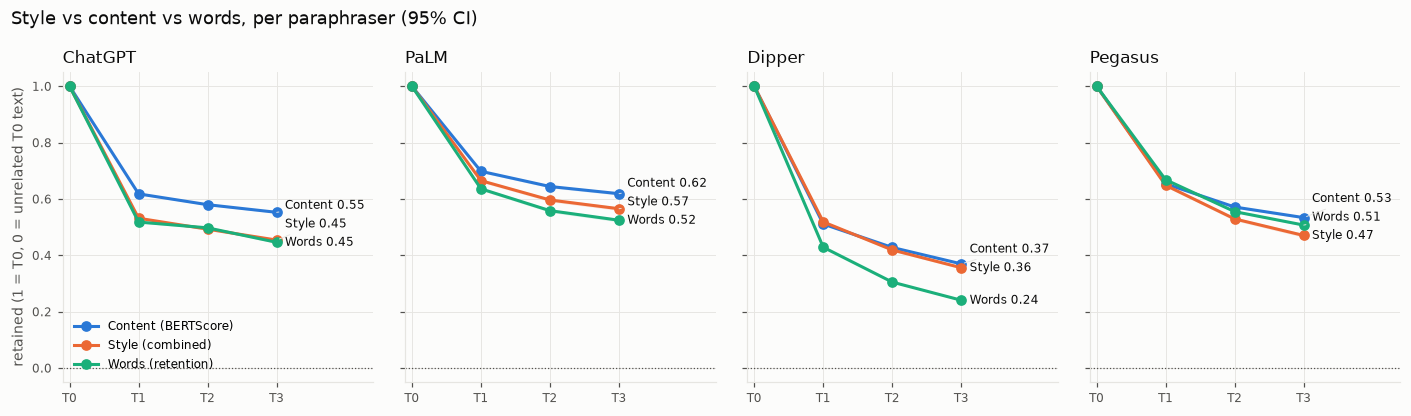

round,1,2,3
variant,,,
chatgpt,"0.086 [0.083, 0.090]","0.087 [0.083, 0.090]","0.099 [0.095, 0.102]"
dipper,"-0.008 [-0.011, -0.004]","0.009 [0.005, 0.013]","0.014 [0.010, 0.018]"
palm,"0.033 [0.030, 0.036]","0.048 [0.045, 0.051]","0.053 [0.050, 0.057]"
pegasus(full),"0.005 [0.002, 0.009]","0.042 [0.039, 0.046]","0.063 [0.059, 0.068]"


In [11]:
# 3.1 Style vs content per paraphraser, and the decay gap (content - style).
FAM_COLOR = {"bertscore_f1_rescaled": "#2a78d6", "style": "#eb6834", "word_retention": "#1baf7a"}  # 3 slots: valid all-pairs
FAM_LABEL = {"bertscore_f1_rescaled": "Content (BERTScore)", "style": "Style (combined)", "word_retention": "Words (retention)"}

fig, axes = plt.subplots(1, 4, figsize=(13, 3.8), sharey=True)
for ax, v in zip(axes, PRIMARY):
    ends = []
    for m, c in FAM_COLOR.items():
        d = curves[(curves.metric == m) & (curves.variant == v)].sort_values("round")
        ax.fill_between([0, *d["round"]], [1, *d.ci_low], [1, *d.ci_high], color=c, alpha=0.15, linewidth=0)
        ax.plot([0, *d["round"]], [1, *d["mean"]], color=c, marker="o", label=FAM_LABEL[m])
        ends.append((FAM_LABEL[m].split(" ")[0], d["mean"].iloc[-1], c))
    label_ends(ax, ends, 3, min_gap=0.065)
    ax.set_xticks([0, 1, 2, 3], ["T0", "T1", "T2", "T3"]); ax.set_xlim(-0.1, 4.4); ax.set_title(LABEL[v], loc="left")
    ax.axhline(0, color=MUTED, linewidth=0.8, linestyle=":")
axes[0].set_ylabel("retained (1 = T0, 0 = unrelated T0 text)"); axes[0].legend(loc="lower left")
fig.suptitle("Style vs content vs words, per paraphraser (95% CI)", x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()

cum = cum.assign(decay_gap=cum.bertscore_f1_rescaled_ret - cum.style_ret)
decay_gap = bootstrap_mean_ci(cum[cum.variant.isin(PRIMARY)], ["variant", "round"], "decay_gap")
save(fig, "style_vs_content", decay_gap)
plt.show()
print("decay gap = retained content - retained style (mean [95% CI]):")
decay_gap.assign(ci=lambda d: d.apply(lambda r: f"{r['mean']:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]", axis=1)
                 ).pivot(index="variant", columns="round", values="ci")

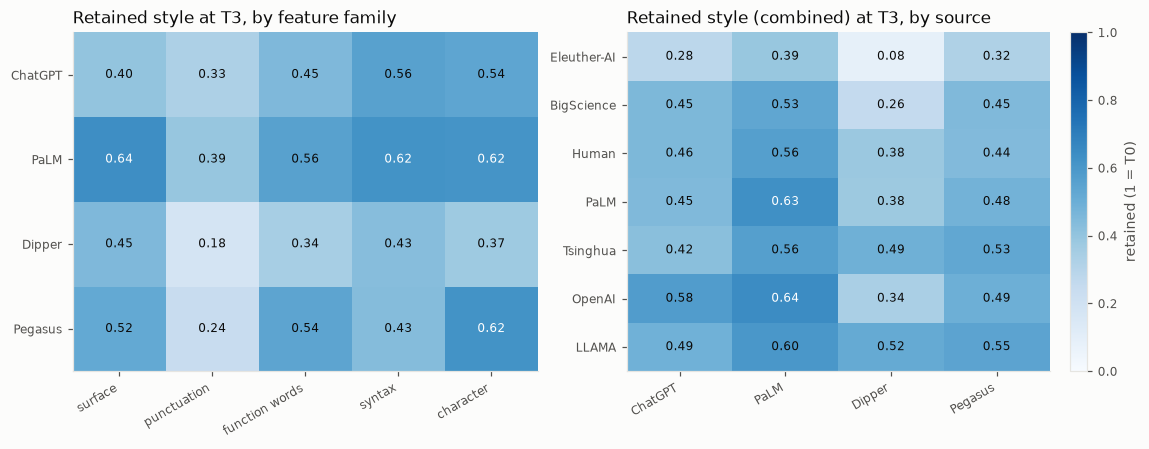

,Surface (z-cosine),Punctuation (z-cosine),Punctuation L1,Function words (z-cosine),Function-word cosine,Burrows' Delta,POS (z-cosine),POS JSD,Dependency JSD,Char 2-4-gram TF-IDF,Char 3-gram cosine
variant,,,,,,,,,,,
chatgpt,0.401,0.327,0.328,0.435,0.514,0.399,0.548,0.630,0.488,0.540,0.533
palm,0.637,0.403,0.382,0.577,0.605,0.493,0.638,0.657,0.568,0.620,0.614
dipper,0.451,0.187,0.170,0.360,0.417,0.256,0.447,0.482,0.364,0.356,0.391
pegasus(full),0.520,0.335,0.141,0.585,0.607,0.430,0.549,0.364,0.390,0.647,0.589


In [12]:
# 3.2 Which style features go first, and whose style decays fastest (caveat: LLM-authored originals
# begin with the Human text's opening words, their generation prompt).
t3_all = cum[(cum["round"] == 3) & cum.variant.isin(PRIMARY)]
blocks_t3 = t3_all.groupby("variant")[[f"{f}_ret" for f in FAMILIES]].mean().reindex(PRIMARY)
blocks_t3.columns = [f.replace("style_fam_", "").replace("_", " ") for f in FAMILIES]
components_t3 = t3_all.groupby("variant")[[f"{m}_ret" for m in STYLE_COMPONENTS]].mean().reindex(PRIMARY)
components_t3.columns = [NAME[m] for m in STYLE_COMPONENTS]
by_source = t3_all.groupby(["source", "variant"]).style_ret.mean().unstack().reindex(columns=PRIMARY)
by_source = by_source.loc[by_source.mean(axis=1).sort_values().index]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.1, 1]})
for ax, table, title in [(axes[0], blocks_t3, "Retained style at T3, by feature family"),
                         (axes[1], by_source, "Retained style (combined) at T3, by source")]:
    im = ax.imshow(table.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")  # sequential: magnitude
    ax.set_xticks(range(table.shape[1]), [LABEL.get(c, c) for c in table.columns], rotation=30, ha="right")
    ax.set_yticks(range(table.shape[0]), [LABEL.get(i, i) for i in table.index])
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            val = table.iat[i, j]
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=8, color="white" if val > 0.6 else INK)
    ax.grid(False); ax.set_title(title, loc="left")
fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02, label="retained (1 = T0)")
save(fig, "style_blocks_and_sources", by_source.reset_index())
blocks_t3.round(3).to_csv(OUT / "style_blocks_T3.csv")
components_t3.round(3).to_csv(OUT / "style_components_T3.csv")
plt.show()
components_t3.round(3)

## 4. Information preservation and Samer's extra metrics

Samer's RQ1 metrics, on the same retained scale as everything else. **These are heuristic warnings, not validated factual errors.**
- **Entity recall:** share of the original's named entities (spaCy, normalized) still found verbatim in the rewrite. Paraphrases and spelling variants count as losses.
- **Number / quantity recall:** clipped multiset recall of normalized numbers and of number+unit quantities.
- **Sentence coverage:** share of original sentences whose best MPNet match in the rewrite reaches cosine 0.6.

The flag rates are raw shares of pairs with at least one lost entity, a changed number set, or an uncovered sentence; they are not normalized. Recalls are undefined when the original has no entities, numbers or quantities, and those pairs are skipped.

Share of pairs with a content warning vs T0 (heuristic):


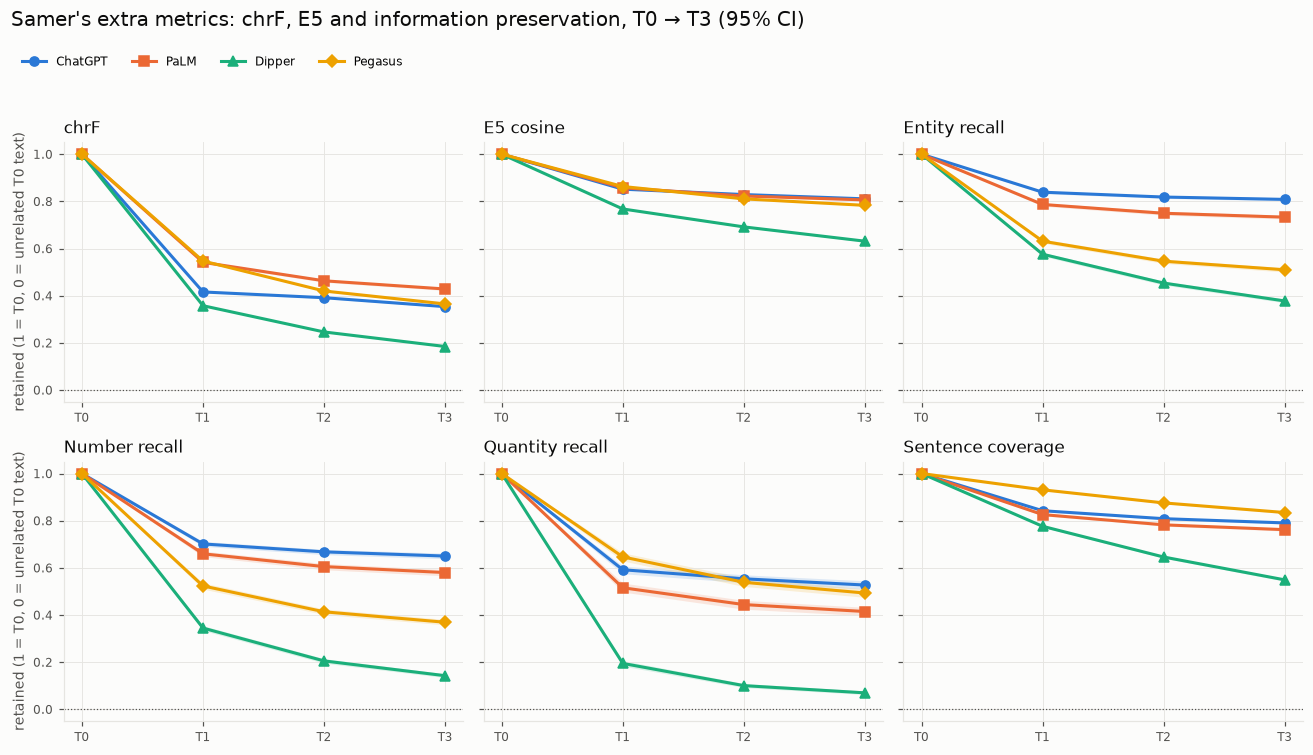

entity_loss  number_change  sentence_omission  \
variant       round                                                  
chatgpt       1            0.322          0.260              0.586   
              2            0.351          0.283              0.639   
              3            0.363          0.295              0.666   
dipper        1            0.604          0.481              0.775   
              2            0.667          0.511              0.885   
              3            0.699          0.525              0.925   
palm          1            0.341          0.277              0.525   
              2            0.386          0.311              0.593   
              3            0.405          0.329              0.624   
pegasus(full) 1            0.561          0.406              0.420   
              2            0.611          0.457              0.592   
              3            0.631          0.476              0.679   

                     any_content_warning  
variant       round                       
chatgpt       1                    0.694  
              2                    0.744  
              3                    0.770  
dipper        1                    0.905  
              2                    0.953  
              3                    0.970  
palm          1                    0.658  
              2                    0.724  
              3                    0.754  
pegasus(full) 1                    0.758  
              2                    0.836  
              3                    0.867

In [13]:
# 4.1 Information decay curves (retained, 95% CI) and content-warning rates
INFO_PANELS = ["chrf", "e5_cosine", "entity_recall", "number_recall", "quantity_recall", "sent_coverage"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.8), sharey=True)
for ax, m in zip(axes.flat, INFO_PANELS):
    plot_curves(ax, m, PRIMARY, COLOR, MARKER)
for ax in axes[:, 0]:
    ax.set_ylabel("retained (1 = T0, 0 = unrelated T0 text)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.01, 0.955), ncol=4)
fig.suptitle("Samer's extra metrics: chrF, E5 and information preservation, T0 → T3 (95% CI)", x=0.01, ha="left",
             fontsize=13, color=INK, y=1.0)
fig.tight_layout(rect=(0, 0, 1, 0.92))

cum_p = cum[cum.variant.isin(PRIMARY)]
flags = (cum_p.groupby(["variant", "round"])[FLAGS + ["flag_any_content_warning"]].mean()
         .rename(columns=lambda c: c.replace("flag_", "")))
save(fig, "information_curves", flags.reset_index())
plt.show()
print("Share of pairs with a content warning vs T0 (heuristic):")
flags.round(3)

In [14]:
# 4.2 Round-to-round change (Samer's convergence measures): word edit rate and exact equality per step,
# and the share of the total T0->T3 loss that happens in round 1.
step = scores[(scores.kind == "step") & scores.variant.isin(PRIMARY)]
first = scores[(scores.kind == "cumulative") & (scores["round"] == 1) & scores.variant.isin(PRIMARY)]
steps = pd.concat([first.assign(step="T0→T1"),
                   step.assign(step=step["round"].map({2: "T1→T2", 3: "T2→T3"}))])
conv = steps.groupby(["variant", "step"])[["word_edit_rate", "exact_equal"]].mean().unstack("step").round(3)

m_cum = cum_p.groupby(["variant", "round"])[["chrf", "bertscore_f1_rescaled"]].mean()
share = pd.DataFrame({f"round-1 share of T3 loss ({c})": (1 - m_cum[c].xs(1, level="round")) / (1 - m_cum[c].xs(3, level="round"))
                      for c in ["chrf", "bertscore_f1_rescaled"]}).round(3)
conv.to_csv(OUT / "convergence_steps.csv"); share.to_csv(OUT / "convergence_round1_share.csv")
display(conv.rename(index=LABEL))
share.rename(index=LABEL)

word_edit_rate               exact_equal              
step             T0→T1  T1→T2  T2→T3       T0→T1  T1→T2  T2→T3
variant                                                       
ChatGPT          0.707  0.413  0.364         0.0  0.000  0.000
Dipper           0.878  0.860  0.834         0.0  0.000  0.000
PaLM             0.533  0.261  0.191         0.0  0.006  0.024
Pegasus          0.528  0.392  0.329         0.0  0.009  0.025

,round-1 share of T3 loss (chrf),round-1 share of T3 loss (bertscore_f1_rescaled)
variant,,
ChatGPT,0.904,0.854
Dipper,0.788,0.776
PaLM,0.802,0.792
Pegasus,0.714,0.744


## 5. Round-trip translation vs paraphrase on the same originals

Samer's RQ1 ran three translators (MADLAD-400-3B, NLLB-200-1.3B, Qwen3-4B) through three English → Spanish → English round trips on 200 XSum T0 documents from this corpus. His translations aren't in the repo, but his branch publishes text-free per-pair scores keyed by text hash, plus the manifest that maps each document to (dataset, source, key). `scripts/import_samer_rq1.py` extracts both.

- **Same originals:** all 200 of his T0 texts are byte-identical (SHA-256) to ours.
- **Same metrics:** the script rescores his 368 baseline pairs (all T0 texts) with `pilot.metrics`, and the table below compares the results pair by pair. Only metrics that agree are used here. Word retention (his counts all tokens, ours content words only) and the combined style score (it needs the texts) are left out until his package follows the standard.
- **Same scale:** his raw scores are put on the retained scale with **our** XSum floors, so translation and paraphrase share one 0-1 scale.
- **Cohort:** documents complete to T3 for all three translators *and* all four paraphrasers. CIs resample the original article (`key`).

In [15]:
# 5.1 Load Samer's translation scores (python scripts/import_samer_rq1.py), check agreement, put them on our scale
need = ["samer_pair_metrics.parquet", "samer_items.csv", "samer_baselines_rescored.parquet"]
assert all((DERIVED / f).exists() for f in need), "run: PYTHONPATH=src python scripts/import_samer_rq1.py"
spm = pd.read_parquet(DERIVED / "samer_pair_metrics.parquet")
items = pd.read_csv(DERIVED / "samer_items.csv")
TRANSLATORS = ["madlad-3b", "nllb", "qwen3-4b"]
LABEL.update({"madlad-3b": "MADLAD-400-3B", "nllb": "NLLB-200-1.3B", "qwen3-4b": "Qwen3-4B"})
COLOR.update({"madlad-3b": "#e87ba4", "nllb": "#008300", "qwen3-4b": "#6250d6"})   # categorical slots 5-7
MARKER.update({"madlad-3b": "v", "nllb": "P", "qwen3-4b": "X"})

# Per-pair agreement of his scores with ours on his baseline pairs (identical T0 texts on both sides)
SHARED = ["bleu", "rougeL", "chrf", "word_edit_rate", "bertscore_f1_rescaled", "mpnet_cosine", "e5_cosine",
          "entity_recall", "number_recall", "quantity_recall", "sent_coverage"]
ours_b = pd.read_parquet(DERIVED / "samer_baselines_rescored.parquet")
his_b = spm[spm.kind.isin(["unrelated", "cross_source"])].reset_index(drop=True).assign(floor_id=lambda d: range(len(d)))
ab = ours_b.merge(his_b, on="floor_id", suffixes=("_ours", "_samer"), validate="1:1")
assert (ab.ref_sha256_ours == ab.ref_sha256_samer).all()
agree = pd.DataFrame({m: {"max |ours - Samer|": (ab[f"{m}_ours"] - ab[f"{m}_samer"]).abs().max(),
                          "NaN mismatches": int((ab[f"{m}_ours"].isna() != ab[f"{m}_samer"].isna()).sum())}
                      for m in SHARED + ["word_retention"]}).T
agree.round(4).rename_axis("metric").reset_index().to_csv(OUT / "samer_metric_agreement.csv", index=False)
assert (agree.loc[SHARED, "max |ours - Samer|"] < 1e-3).all(), "a shared metric no longer matches Samer's"

# Translation pairs -> the analysis frame's shape (key = article; source/key from the item id)
tr = spm[spm.translator.isin(TRANSLATORS) & spm.kind.isin(["cumulative", "step"])].copy()
tr[["dataset", "source", "key"]] = tr.item_id.str.split("|", expand=True)
tr = tr.rename(columns={"translator": "variant"})
xsum_floor = floor.loc["xsum"]
for m in SHARED:
    tr[f"{m}_ret"] = retained(tr[m], xsum_floor[m], m)

# Cohort: complete to T3 for every translator and every primary paraphraser
t3 = tr[(tr.kind == "cumulative") & (tr["round"] == 3)]
complete_tr = set.intersection(*(set(t3[t3.variant == v].item_id) for v in TRANSLATORS))
sot_ids = set("xsum|" + sample[sample.dataset == "xsum"].source + "|" + sample[sample.dataset == "xsum"].key)
COHORT = sorted(complete_tr & sot_ids)
para = scores[scores.dataset.eq("xsum") & scores.variant.isin(PRIMARY)].copy()
para["item_id"] = "xsum|" + para.source + "|" + para.key
both = pd.concat([para[para.item_id.isin(COHORT)], tr[tr.item_id.isin(COHORT)]], ignore_index=True)
REWRITERS = PRIMARY + TRANSLATORS
print(f"cohort: {len(COHORT)} documents on {both.key.nunique()} articles "
      f"(Samer: {len(items)} documents; complete for all translators: {len(complete_tr)}; SoT completers: "
      f"{len(set(items.item_id) & sot_ids)})")
print("Per-pair agreement on Samer's 368 baseline pairs (identical texts):")
agree.round(4)

cohort: 178 documents on 31 articles (Samer: 200 documents; complete for all translators: 193; SoT completers: 184)
Per-pair agreement on Samer's 368 baseline pairs (identical texts):


,max |ours - Samer|,NaN mismatches
bleu,0.0000,0.0
rougeL,0.0000,0.0
chrf,0.0000,0.0
word_edit_rate,0.0000,0.0
bertscore_f1_rescaled,0.0005,0.0
mpnet_cosine,0.0000,0.0
e5_cosine,0.0000,0.0
entity_recall,0.0000,0.0
number_recall,0.0000,0.0
quantity_recall,0.0000,0.0


Retained at T3, mean [95% CI]:
Translation - paraphrase at T3 (per-document family means; CI resamples articles):
Word edit rate between consecutive rounds:


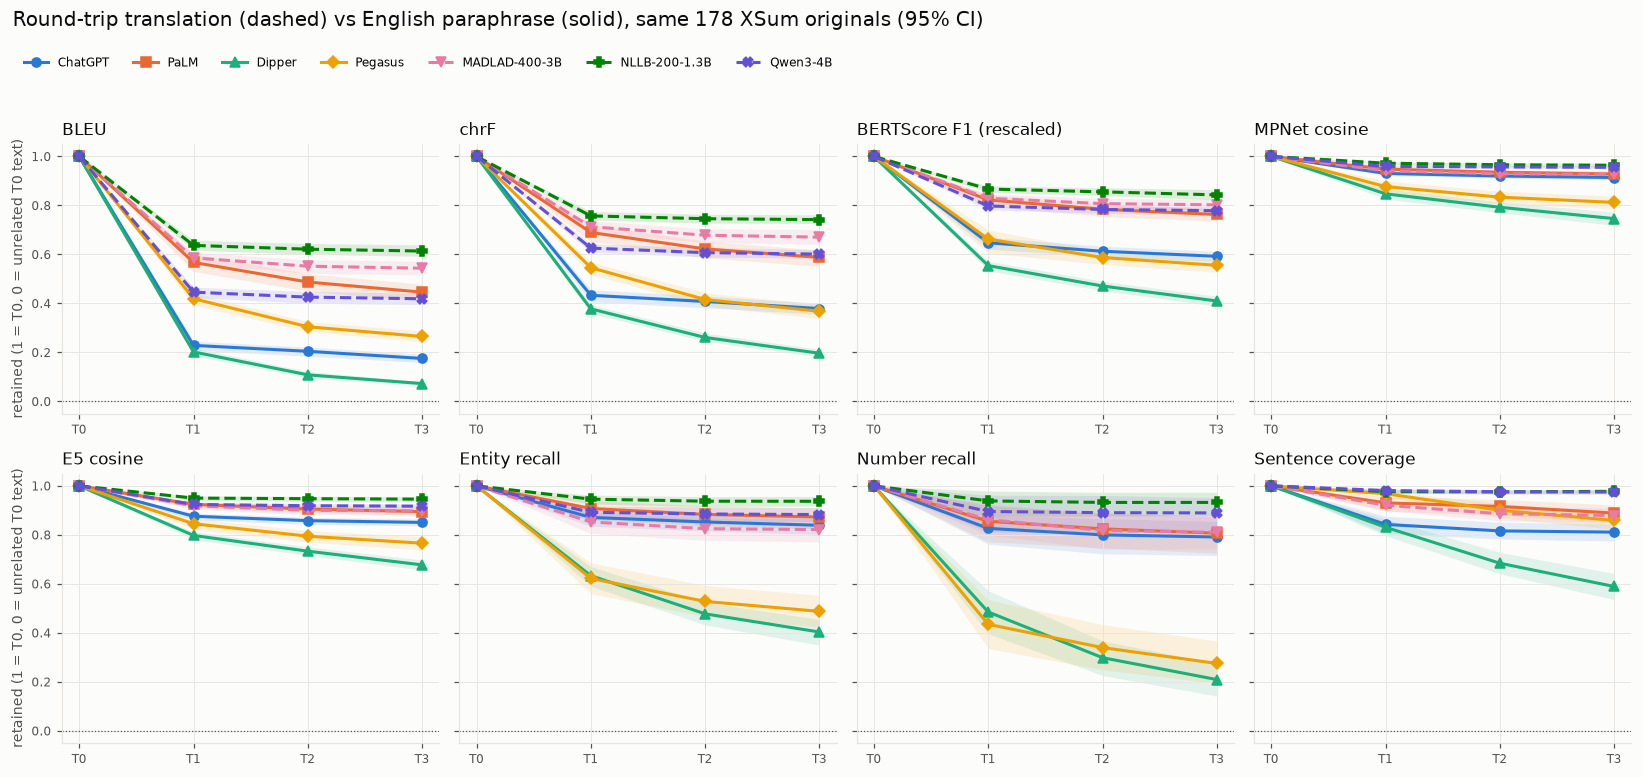

metric,BLEU,chrF,BERTScore F1 (rescaled),MPNet cosine,E5 cosine,Entity recall,Number recall,Sentence coverage
variant,,,,,,,,
ChatGPT,"0.18 [0.16, 0.19]","0.38 [0.36, 0.40]","0.59 [0.57, 0.61]","0.91 [0.90, 0.92]","0.85 [0.84, 0.86]","0.84 [0.80, 0.87]","0.79 [0.72, 0.85]","0.81 [0.77, 0.85]"
PaLM,"0.45 [0.41, 0.48]","0.59 [0.55, 0.62]","0.76 [0.74, 0.78]","0.93 [0.92, 0.94]","0.89 [0.88, 0.91]","0.87 [0.82, 0.91]","0.81 [0.72, 0.87]","0.89 [0.85, 0.92]"
Dipper,"0.07 [0.07, 0.08]","0.20 [0.18, 0.21]","0.41 [0.39, 0.43]","0.75 [0.72, 0.77]","0.68 [0.66, 0.70]","0.40 [0.35, 0.45]","0.21 [0.14, 0.28]","0.59 [0.54, 0.64]"
Pegasus,"0.27 [0.24, 0.29]","0.37 [0.34, 0.40]","0.56 [0.53, 0.58]","0.81 [0.79, 0.84]","0.77 [0.74, 0.79]","0.49 [0.42, 0.55]","0.28 [0.19, 0.37]","0.86 [0.82, 0.89]"
MADLAD-400-3B,"0.54 [0.52, 0.57]","0.67 [0.64, 0.70]","0.80 [0.78, 0.83]","0.93 [0.91, 0.94]","0.90 [0.88, 0.92]","0.82 [0.77, 0.87]","0.81 [0.74, 0.88]","0.88 [0.85, 0.91]"
NLLB-200-1.3B,"0.61 [0.59, 0.64]","0.74 [0.73, 0.76]","0.84 [0.82, 0.86]","0.96 [0.96, 0.97]","0.95 [0.94, 0.96]","0.94 [0.92, 0.96]","0.93 [0.88, 0.97]","0.98 [0.97, 0.99]"
Qwen3-4B,"0.42 [0.39, 0.44]","0.60 [0.58, 0.62]","0.78 [0.76, 0.79]","0.96 [0.95, 0.96]","0.92 [0.91, 0.93]","0.88 [0.86, 0.91]","0.89 [0.82, 0.95]","0.97 [0.97, 0.98]"


,metric,translation,paraphrase,gap,ci_low,ci_high,n_docs
0,BLEU,0.525,0.240,0.286,0.268,0.303,178
1,chrF,0.671,0.383,0.288,0.274,0.303,178
2,BERTScore F1 (rescaled),0.808,0.580,0.228,0.216,0.240,178
3,MPNet cosine,0.949,0.850,0.099,0.089,0.108,178
4,E5 cosine,0.920,0.797,0.123,0.114,0.132,178
5,Entity recall,0.880,0.651,0.230,0.194,0.263,174
6,Number recall,0.877,0.521,0.357,0.322,0.392,148
7,Sentence coverage,0.944,0.787,0.157,0.131,0.182,178


round,T0→T1,T1→T2,T2→T3
variant,,,
ChatGPT,0.724,0.418,0.349
PaLM,0.369,0.182,0.155
Dipper,0.903,0.997,0.863
Pegasus,0.535,0.386,0.285
MADLAD-400-3B,0.305,0.079,0.023
NLLB-200-1.3B,0.249,0.040,0.021
Qwen3-4B,0.437,0.100,0.038


In [16]:
# 5.2 Decay curves for translators (dashed) and paraphrasers (solid) on the same documents, T3 gap, step change
TP = ["bleu", "chrf", "bertscore_f1_rescaled", "mpnet_cosine", "e5_cosine", "entity_recall", "number_recall",
      "sent_coverage"]
bcum = both[both.kind == "cumulative"]
tcurves = pd.concat([bootstrap_mean_ci(bcum, ["variant", "round"], f"{m}_ret").assign(metric=m) for m in TP],
                    ignore_index=True)
DASH = {v: "--" for v in TRANSLATORS}

fig, axes = plt.subplots(2, 4, figsize=(15, 7), sharey=True)
for ax, m in zip(axes.flat, TP):
    for v in REWRITERS:
        d = tcurves[(tcurves.metric == m) & (tcurves.variant == v)].sort_values("round")
        ax.fill_between([0, *d["round"]], [1, *d.ci_low], [1, *d.ci_high], color=COLOR[v], alpha=0.12, linewidth=0)
        ax.plot([0, *d["round"]], [1, *d["mean"]], color=COLOR[v], marker=MARKER[v], linestyle=DASH.get(v, "-"),
                label=LABEL[v])
    ax.set_xticks([0, 1, 2, 3], ["T0", "T1", "T2", "T3"]); ax.set_title(NAME[m], loc="left")
    ax.axhline(0, color=MUTED, linewidth=0.8, linestyle=":")
for ax in axes[:, 0]:
    ax.set_ylabel("retained (1 = T0, 0 = unrelated T0 text)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.01, 0.955), ncol=7)
fig.suptitle(f"Round-trip translation (dashed) vs English paraphrase (solid), same {len(COHORT)} XSum originals "
             "(95% CI)", x=0.01, ha="left", fontsize=13, color=INK, y=1.0)
fig.tight_layout(rect=(0, 0, 1, 0.92))
save(fig, "translation_vs_paraphrase", tcurves)
plt.show()

# Paired gap at T3, per document: mean over the 3 translators - mean over the 4 paraphrasers (CI over articles)
b3 = bcum[bcum["round"] == 3].assign(family=lambda d: np.where(d.variant.isin(TRANSLATORS), "translation", "paraphrase"))
fam = b3.groupby(["item_id", "key", "family"])[[f"{m}_ret" for m in TP]].mean().unstack("family")
gap_rows = []
for m in TP:
    g = (fam[(f"{m}_ret", "translation")] - fam[(f"{m}_ret", "paraphrase")]).dropna().rename("gap").reset_index()
    r = bootstrap_mean_ci(g.assign(all="all"), ["all"], "gap").iloc[0]
    gap_rows.append({"metric": NAME[m], "translation": fam[(f"{m}_ret", "translation")].mean(),
                     "paraphrase": fam[(f"{m}_ret", "paraphrase")].mean(), "gap": r["mean"],
                     "ci_low": r.ci_low, "ci_high": r.ci_high, "n_docs": r.n})
gap = pd.DataFrame(gap_rows)
gap.round(4).to_csv(OUT / "translation_vs_paraphrase_T3_gap.csv", index=False)

# Round-to-round change: word edit rate per step (convergence)
# (the SoT pairs store T0→T1 only as a cumulative pair; Samer's tables store it as both)
step_rows = pd.concat([both[(both.kind == "step") & (both["round"] > 1)],
                       both[(both.kind == "cumulative") & (both["round"] == 1)]])
steps = (step_rows.groupby(["variant", "round"]).word_edit_rate.mean().unstack()
         .rename(columns={1: "T0→T1", 2: "T1→T2", 3: "T2→T3"}).reindex(REWRITERS).rename(index=LABEL))
steps.round(4).reset_index().to_csv(OUT / "translation_vs_paraphrase_steps.csv", index=False)

t3_table = (tcurves[tcurves["round"] == 3].assign(cell=lambda d: d["mean"].map("{:.2f}".format) + " [" +
            d.ci_low.map("{:.2f}".format) + ", " + d.ci_high.map("{:.2f}".format) + "]")
            .pivot(index="variant", columns="metric", values="cell").reindex(REWRITERS)[TP]
            .rename(index=LABEL, columns=NAME))
print("Retained at T3, mean [95% CI]:")
display(t3_table)
print("Translation - paraphrase at T3 (per-document family means; CI resamples articles):")
display(gap.round(3))
print("Word edit rate between consecutive rounds:")
steps.round(3)